# CS461 Final Project: Lunar Lander

Installing Dependencies

In [ ]:
!apt-get install -y python3-dev swig

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
python3-dev is already the newest version (3.10.6-1~22.04.1).
python3-dev set to manually installed.
Suggested packages:
  swig-doc swig-examples swig4.0-examples swig4.0-doc
The following NEW packages will be installed:
  swig swig4.0
0 upgraded, 2 newly installed, 0 to remove and 49 not upgraded.
Need to get 1,116 kB of archives.
After this operation, 5,542 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 swig4.0 amd64 4.0.2-1ubuntu1 [1,110 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 swig all 4.0.2-1ubuntu1 [5,632 B]
Fetched 1,116 kB in 1s (838 kB/s)
Selecting previously unselected package swig4.0.
(Reading database ... 123634 files and directories currently installed.)
Preparing to unpack .../swig4.0_4.0.2-1ubuntu1_amd64.deb ...
Unpacking swig4.0 (4.0.2-1ubuntu1) ...
Selecting previously unselected package swig.
Pre

In [ ]:
# Install required libraries
!pip install gymnasium[box2d] stable-baselines3 torch numpy matplotlib


  Using cached stable_baselines3-2.4.0-py3-none-any.whl.metadata (4.5 kB)
  Using cached gymnasium-1.0.0-py3-none-any.whl.metadata (9.5 kB)
  Using cached Farama_Notifications-0.0.4-py3-none-any.whl.metadata (558 bytes)
  Using cached box2d-py-2.3.5.tar.gz (374 kB)
  Preparing metadata (setup.py) ... done
  Using cached swig-4.3.0-py2.py3-none-manylinux_2_5_x86_64.manylinux1_x86_64.whl.metadata (3.5 kB)
Using cached swig-4.3.0-py2.py3-none-manylinux_2_5_x86_64.manylinux1_x86_64.whl (1.9 MB)
Using cached stable_baselines3-2.4.0-py3-none-any.whl (183 kB)
Using cached Farama_Notifications-0.0.4-py3-none-any.whl (2.5 kB)
Using cached gymnasium-1.0.0-py3-none-any.whl (958 kB)
  Created wheel for box2d-py: filename=box2d_py-2.3.5-cp310-cp310-linux_x86_64.whl size=2349145 sha256=9b4a9cfe6fe8c4fb1f2966bf8e86dcf1bcbede299987604270766443c88c1d02
  Stored in directory: /root/.cache/pip/wheels/db/8f/6a/eaaadf056fba10a98d986f6dce954e6201ba3126926fc5ad9e
Successfully built box2d-py


In [ ]:
!pip install gymnasium[box2d]
!pip install torch --upgrade
!pip install matplotlib


In [ ]:
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import random
import copy
import matplotlib.pyplot as plt


%matplotlib inline


# Coding The Different Parts TD3 Needs

In [ ]:
#the actor neural network responsible from approximating the actions giving states
class Actor(nn.Module):
    def __init__(self, state_dim, action_dim, max_action):
        super(Actor, self).__init__()
        self.fc1 = nn.Linear(state_dim, 400)
        self.fc2 = nn.Linear(400, 300)
        self.fc3 = nn.Linear(300, action_dim)
        self.max_action = max_action
    #network update
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        # Scale output to action range
        return self.max_action * torch.tanh(x)

#the critic neural network responsible from approximationg Q values given state, action
class Critic(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(Critic, self).__init__()
        #We have two Q networks
        # Q1 architecture
        self.fc1_1 = nn.Linear(state_dim + action_dim, 400)
        self.fc1_2 = nn.Linear(400, 300)
        self.fc1_3 = nn.Linear(300, 1)
        # Q2 architecture
        self.fc2_1 = nn.Linear(state_dim + action_dim, 400)
        self.fc2_2 = nn.Linear(400, 300)
        self.fc2_3 = nn.Linear(300, 1)
    #network update
    def forward(self, x, a):
        xa1 = torch.cat([x, a], dim=1)
        q1 = F.relu(self.fc1_1(xa1))
        q1 = F.relu(self.fc1_2(q1))
        q1 = self.fc1_3(q1)

        xa2 = torch.cat([x, a], dim=1)
        q2 = F.relu(self.fc2_1(xa2))
        q2 = F.relu(self.fc2_2(q2))
        q2 = self.fc2_3(q2)

        return q1, q2

    def Q1(self, x, a):
        xa1 = torch.cat([x, a], dim=1)
        q1 = F.relu(self.fc1_1(xa1))
        q1 = F.relu(self.fc1_2(q1))
        q1 = self.fc1_3(q1)
        return q1

#store the past experience in the replay buffer

class ReplayBuffer(object):
    def __init__(self, max_size, state_dim, action_dim):
        self.max_size = int(max_size)
        self.ptr = 0
        self.size = 0
        self.state = np.zeros((self.max_size, state_dim))
        self.action = np.zeros((self.max_size, action_dim))
        self.next_state = np.zeros((self.max_size, state_dim))
        self.reward = np.zeros((self.max_size, 1))
        self.not_done = np.zeros((self.max_size, 1))
    #store state, action, next_state, reward, termination feedback
    def add(self, state, action, next_state, reward, done):
        self.state[self.ptr] = state
        self.action[self.ptr] = action
        self.next_state[self.ptr] = next_state
        self.reward[self.ptr] = reward
        self.not_done[self.ptr] = 1. - done

        self.ptr = (self.ptr + 1) % self.max_size
        self.size = min(self.size + 1, self.max_size)

    #how to sample from the batch
    def sample(self, batch_size=64):
        ind = np.random.randint(0, self.size, size=batch_size)
        return (
            self.state[ind],
            self.action[ind],
            self.next_state[ind],
            self.reward[ind],
            self.not_done[ind]
        )

#the agent uing above classes
class TD3(object):
    def __init__(
        self,
        state_dim,
        action_dim,
        max_action,
        discount=0.99,
        tau=0.005,
        policy_noise=0.2,
        noise_clip=0.5,
        policy_freq=2
    ):
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.actor = Actor(state_dim, action_dim, max_action).to(device)
        self.actor_target = copy.deepcopy(self.actor)

        self.critic = Critic(state_dim, action_dim).to(device)
        self.critic_target = copy.deepcopy(self.critic)

        self.actor_optimizer = optim.Adam(self.actor.parameters(), lr=1e-3)
        self.critic_optimizer = optim.Adam(self.critic.parameters(), lr=1e-3)

        self.max_action = max_action
        self.discount = discount
        self.tau = tau
        self.policy_noise = policy_noise
        self.noise_clip = noise_clip
        self.policy_freq = policy_freq

        self.total_it = 0
        self.device = device

    def select_action(self, state):
        state = torch.FloatTensor(state).unsqueeze(0).to(self.device)
        action = self.actor(state).detach().cpu().numpy().flatten()
        return action

    def train(self, replay_buffer, batch_size=100):
        self.total_it += 1

        # Sample a batch of transitions
        state, action, next_state, reward, not_done = replay_buffer.sample(batch_size)
        state = torch.FloatTensor(state).to(self.device)
        action = torch.FloatTensor(action).to(self.device)
        next_state = torch.FloatTensor(next_state).to(self.device)
        reward = torch.FloatTensor(reward).to(self.device)
        not_done = torch.FloatTensor(not_done).to(self.device)

        # Select action according to policy and add clipped noise
        noise = (torch.randn_like(action) * self.policy_noise).clamp(-self.noise_clip, self.noise_clip)
        next_action = (self.actor_target(next_state) + noise).clamp(-self.max_action, self.max_action)

        # Compute the target Q value
        target_Q1, target_Q2 = self.critic_target(next_state, next_action)
        target_Q = torch.min(target_Q1, target_Q2)
        target_Q = reward + not_done * self.discount * target_Q

        # Get current Q estimates
        current_Q1, current_Q2 = self.critic(state, action)

        # Compute critic loss
        critic_loss = F.mse_loss(current_Q1, target_Q) + F.mse_loss(current_Q2, target_Q)

        # Optimize the critic
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        self.critic_optimizer.step()

        # Delayed policy updates
        if self.total_it % self.policy_freq == 0:
            # Compute actor loss
            actor_loss = -self.critic.Q1(state, self.actor(state)).mean()
            self.actor_optimizer.zero_grad()
            actor_loss.backward()
            self.actor_optimizer.step()

            # Update the frozen target models
            for param, target_param in zip(self.critic.parameters(), self.critic_target.parameters()):
                target_param.data.copy_(self.tau * param.data + (1 - self.tau) * target_param.data)
            for param, target_param in zip(self.actor.parameters(), self.actor_target.parameters()):
                target_param.data.copy_(self.tau * param.data + (1 - self.tau) * target_param.data)


NameError: name 'nn' is not defined

# The Training Loop

In [ ]:
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    random.seed(seed)

def evaluate_policy(agent, env_name="LunarLanderContinuous-v3", eval_episodes=10):
    eval_env = gym.make(env_name)
    device = agent.device
    avg_reward = 0.0

    for _ in range(eval_episodes):
        state, _ = eval_env.reset()
        done = False
        truncated = False
        while not (done or truncated):
            # Select action with no noise
            action = agent.select_action(state)
            state, reward, done, truncated, _ = eval_env.step(action)
            avg_reward += reward

    avg_reward /= eval_episodes
    eval_env.close()
    return avg_reward

def train_td3(
    env_name="LunarLanderContinuous-v3",
    seed=0,
    start_timesteps=1e4,
    eval_freq=5000,
    max_timesteps=1e6,
    expl_noise=0.1,
    batch_size=100,
    discount=0.99,
    tau=0.005,
    policy_noise=0.2,
    noise_clip=0.5,
    policy_freq=2
):
    set_seed(seed)

    env = gym.make(env_name)
    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.shape[0]
    max_action = float(env.action_space.high[0])

    # Initialize TD3 agent
    agent = TD3(
        state_dim=state_dim,
        action_dim=action_dim,
        max_action=max_action,
        discount=discount,
        tau=tau,
        policy_noise=policy_noise,
        noise_clip=noise_clip,
        policy_freq=policy_freq
    )

    replay_buffer = ReplayBuffer(max_size=1_000_000,
                                 state_dim=state_dim,
                                 action_dim=action_dim)

    # Tracking evaluation rewards
    evaluations = []
    evals_timestep = []

    state, _ = env.reset()
    episode_reward = 0
    episode_timesteps = 0
    episode_num = 0

    for t in range(int(max_timesteps)):
        episode_timesteps += 1

        # Select action randomly or according to policy
        if t < start_timesteps:
            action = env.action_space.sample()
        else:
            action = agent.select_action(np.array(state))
            # Add exploration noise
            action = (action + np.random.normal(0, expl_noise, size=action_dim)).clip(-max_action, max_action)

        # Step in the environment
        next_state, reward, done, truncated, _ = env.step(action)
        done_bool = float(done or truncated)

        # Store the transition in replay buffer
        replay_buffer.add(state, action, next_state, reward, done_bool)

        state = next_state
        episode_reward += reward

        # Train agent after collecting sufficient data
        if t >= start_timesteps:
            agent.train(replay_buffer, batch_size)

        if done or truncated:
            print(f"Seed: {seed} | Timestep: {t+1} | Episode: {episode_num+1} | Episode T: {episode_timesteps} | Reward: {episode_reward:.2f}")
            state, _ = env.reset()
            episode_reward = 0
            episode_timesteps = 0
            episode_num += 1

        # Evaluate
        if (t + 1) % eval_freq == 0:
            eval_reward = evaluate_policy(agent, env_name=env_name)
            evaluations.append(eval_reward)
            evals_timestep.append(t+1)
            print(f"Evaluation at T={t+1}: {eval_reward:.2f}")

    env.close()
    return evaluations, evals_timestep


# Experimenting With 6 Seeds

Görüntülenen çıkış son 5000 satıra kısaltıldı.
Seed: 842798217 | Timestep: 45518 | Episode: 195 | Episode T: 1000 | Reward: -30.72
Seed: 842798217 | Timestep: 46284 | Episode: 196 | Episode T: 766 | Reward: -93.94
Seed: 842798217 | Timestep: 46841 | Episode: 197 | Episode T: 557 | Reward: -80.28
Seed: 842798217 | Timestep: 47841 | Episode: 198 | Episode T: 1000 | Reward: -97.94
Seed: 842798217 | Timestep: 48118 | Episode: 199 | Episode T: 277 | Reward: -18.21
Seed: 842798217 | Timestep: 48705 | Episode: 200 | Episode T: 587 | Reward: -89.46
Seed: 842798217 | Timestep: 48848 | Episode: 201 | Episode T: 143 | Reward: -32.22
Seed: 842798217 | Timestep: 49185 | Episode: 202 | Episode T: 337 | Reward: -99.50
Seed: 842798217 | Timestep: 49375 | Episode: 203 | Episode T: 190 | Reward: -11.14
Seed: 842798217 | Timestep: 49651 | Episode: 204 | Episode T: 276 | Reward: 9.23
Seed: 842798217 | Timestep: 49927 | Episode: 205 | Episode T: 276 | Reward: 18.37
Evaluation at T=50000: 17.27
Seed: 842798

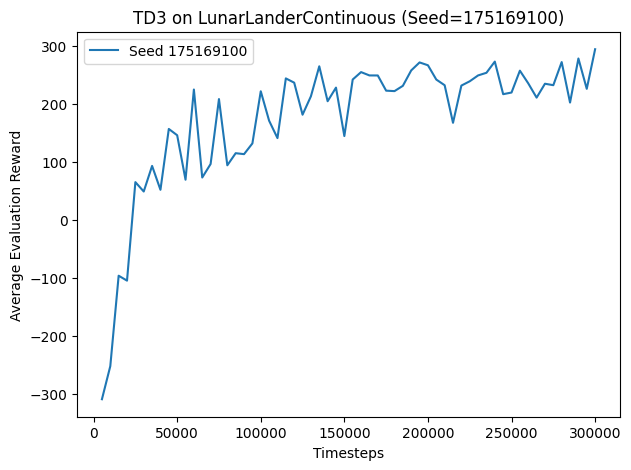

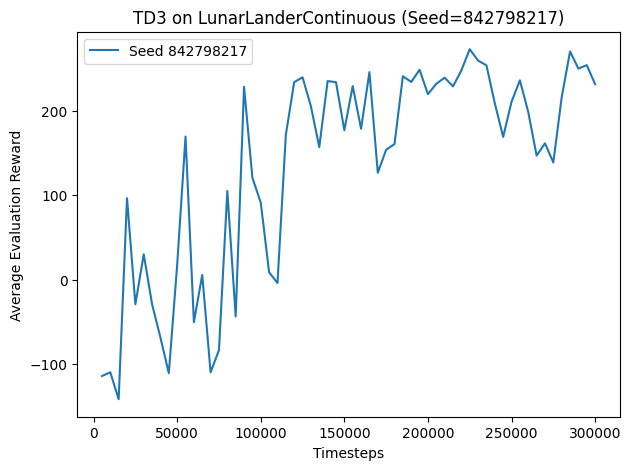

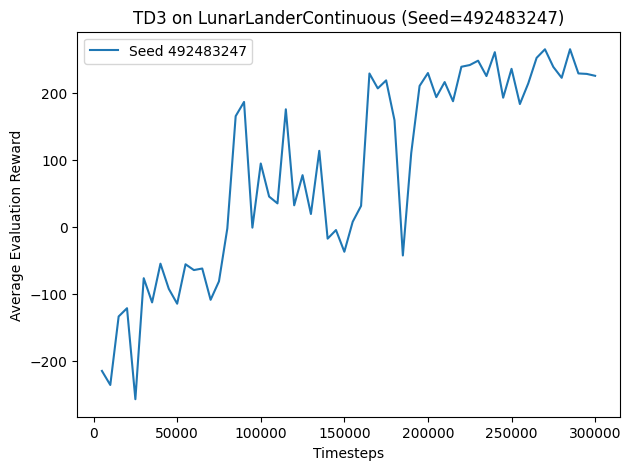

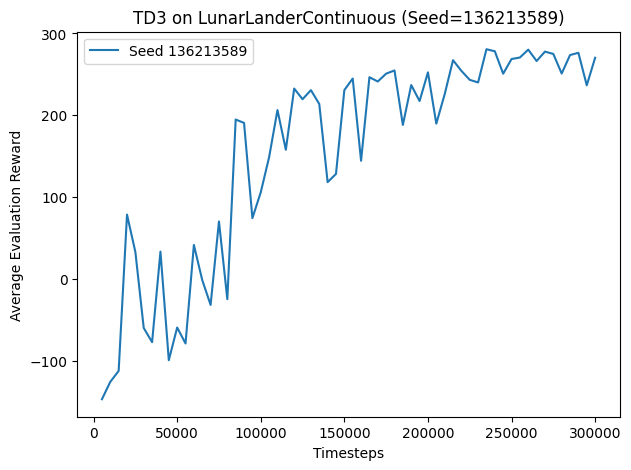

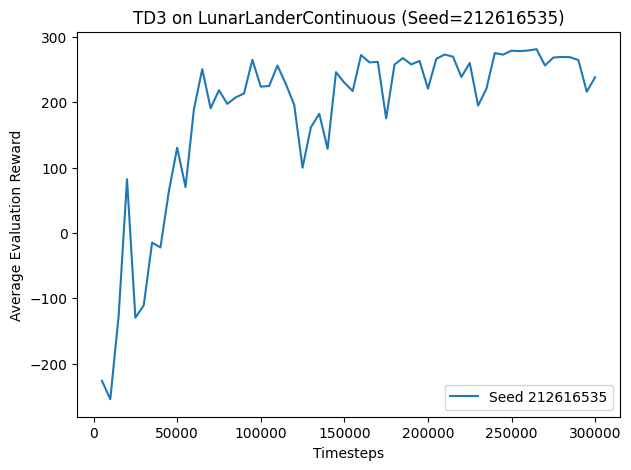

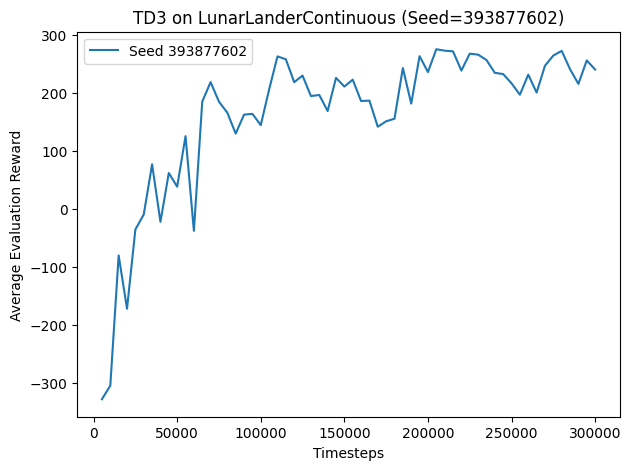

,Seed,Final Evaluation Reward
0,175169100,294.153919
1,842798217,231.961658
2,492483247,224.896537
3,136213589,270.329748
4,212616535,238.275169
5,393877602,240.039505


Average final reward across seeds: 249.94 ± 24.34


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def six_seeds_train_plot():
    """
    1) Generates 6 random seeds.
    2) Trains your TD3 agent once per seed, storing evaluation logs.
    3) Plots separate learning curves for each seed.
    4) Prints/Displays a final summary of results.
    """

    #Generate 6 random seeds
    seeds = np.random.randint(0, 1_000_000_000, size=6).tolist()
    print("Using random seeds:", seeds)

    # This dictionary will hold (timesteps, evaluations) for each seed
    all_evals = {}

    # Track the final reward (e.g., the last evaluation from training) to summarize
    final_scores = []

    #Train once per seed
    for sd in seeds:
        print(f"\n=== Training with seed={sd} ===")
        evaluations, timesteps = train_td3(
            env_name="LunarLanderContinuous-v3",
            seed=sd,
            start_timesteps=1e4,
            eval_freq=5000,
            max_timesteps=3e5,
            expl_noise=0.1,
            batch_size=100,
            discount=0.99,
            tau=0.005,
            policy_noise=0.2,
            noise_clip=0.5,
            policy_freq=2
        )

        # Store results for plotting
        all_evals[sd] = (timesteps, evaluations)

        # The final or best score from the training logs
        final_score = evaluations[-1] if len(evaluations) > 0 else None
        final_scores.append((sd, final_score))

    #Produce the plots
    for idx, sd in enumerate(seeds):
        tsteps, evals = all_evals[sd]
        plt.figure(figsize=(7, 5))
        plt.plot(tsteps, evals, label=f"Seed {sd}")
        plt.xlabel("Timesteps")
        plt.ylabel("Average Evaluation Reward")
        plt.title(f"TD3 on LunarLanderContinuous (Seed={sd})")
        plt.legend()
        plt.show()

    # Summarize results in a table
    df_results = pd.DataFrame(final_scores, columns=["Seed", "Final Evaluation Reward"])
    display(df_results)


    valid_scores = [sc for (_, sc) in final_scores if sc is not None]
    if len(valid_scores) > 0:
        mean_score = np.mean(valid_scores)
        std_score = np.std(valid_scores)
        print(f"Average final reward across seeds: {mean_score:.2f} ± {std_score:.2f}")
    else:
        print("No valid final scores were collected.")


six_seeds_train_plot()
